## DS340H Capstone HW2
Author: QiQi Li
Date : September 12, 2026

In [103]:
import pandas as pd 


In [104]:
df = pd.read_csv("ATUS_roster_subset.csv")
df.head()

,TUCASEID,TULINENO,TEAGE,TERRP,TESEX,Unnamed: 5,Unnamed: 6,Unnamed: 7
0,20240101240107,1,23,19,2,NaN,NaN,NaN
1,20240101240107,2,23,20,1,NaN,NaN,NaN
2,20240101240143,1,21,18,2,NaN,NaN,NaN
3,20240101240143,2,51,24,1,NaN,NaN,NaN
4,20240101240143,3,19,25,2,NaN,NaN,NaN


In [105]:
df_households = df.groupby('TUCASEID')['TULINENO'].count()
df_households

TUCASEID
20240101240107    2
20240101240143    4
20240101240176    3
20240101240237    5
20240101240512    2
                 ..
20241212241757    2
20241212241812    3
20241212242080    1
20241212242082    2
20241212242280    1
Name: TULINENO, Length: 3000, dtype: int64

In [106]:
df_households.max()

np.int64(9)

In [107]:
size_counts = df_households.value_counts().sort_index()
size_counts

TULINENO
1     694
2    1249
3     424
4     388
5     165
6      51
7      17
8       8
9       4
Name: count, dtype: int64

694 households have 1 person, 1249 households have 2 people. 9 people are in the largest household.

What proportion of the households contain at least one person aged 18 or below?

In [108]:
under_18 = df["TEAGE"] <= 18
under_18

0       False
1       False
2       False
3       False
4       False
        ...  
7361     True
7362    False
7363    False
7364    False
7365    False
Name: TEAGE, Length: 7366, dtype: bool

In [109]:
has_minor = under_18.groupby(df["TUCASEID"]).any()
has_minor

TUCASEID
20240101240107    False
20240101240143     True
20240101240176    False
20240101240237     True
20240101240512    False
                  ...  
20241212241757    False
20241212241812     True
20241212242080    False
20241212242082    False
20241212242280    False
Name: TEAGE, Length: 3000, dtype: bool

In [110]:
proportion = has_minor.mean()
proportion

np.float64(0.293)

29.3% of the households contain at least one person aged 18 or below.

What proportion of the people living alone are women?

In [111]:
living = df.groupby("TUCASEID")['TULINENO'].transform("count")
living_alone = df[living == 1]
living_alone

,TUCASEID,TULINENO,TEAGE,TERRP,TESEX,Unnamed: 5,Unnamed: 6,Unnamed: 7
16,20240101240566,1,42,19,2,NaN,NaN,NaN
22,20240101240724,1,47,19,1,NaN,NaN,NaN
25,20240101240851,1,73,19,2,NaN,NaN,NaN
41,20240101241178,1,74,19,2,NaN,NaN,NaN
64,20240101241568,1,80,19,2,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...
7339,20241212240954,1,78,19,2,NaN,NaN,NaN
7346,20241212241039,1,55,19,2,NaN,NaN,NaN
7356,20241212241720,1,80,19,1,NaN,NaN,NaN
7362,20241212242080,1,72,19,1,NaN,NaN,NaN


In [112]:
living_alone_f = (living_alone['TESEX'] == 2).mean()
living_alone_f

np.float64(0.5720461095100865)

57.20% of the people living alone are women.

What proportion of the households have exactly one person over age 18?

In [113]:
is_over_18 = df['TEAGE'] > 18
adult = is_over_18.groupby(df["TUCASEID"]).sum()
adult


TUCASEID
20240101240107    2
20240101240143    3
20240101240176    3
20240101240237    3
20240101240512    2
                 ..
20241212241757    2
20241212241812    2
20241212242080    1
20241212242082    2
20241212242280    1
Name: TEAGE, Length: 3000, dtype: int64

In [114]:
proportion_over_18 = (adult == 1).mean()
proportion_over_18

np.float64(0.27566666666666667)

27.57% of the households have exactly one person over age 18.

Among households with exactly one person over age 18 and at least one person aged 18 or below, what proportion of the people over age 18 are women?

In [115]:
adults_per_hh = (df["TEAGE"]>18).groupby(df['TUCASEID']).sum()
minors_per_hh = (df["TEAGE"] <=18).groupby(df["TUCASEID"]).sum()

In [116]:
target_hh = adults_per_hh[(adults_per_hh == 1) & (minors_per_hh >=1)].index
target_adults = df[(df["TUCASEID"].isin(target_hh)) & (df['TEAGE'] > 18)]


In [117]:
prop_women = (target_adults["TESEX"] == 2).mean()
prop_women

np.float64(0.706766917293233)

Among households with exactly one person over age 18 and at least one person aged 18 or below, 70.68% of the people over age 18 are women.

## Step 3: Examine our self-assessment data

In [118]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
import seaborn as sns
# import all packages for plotting

In [119]:
df_ds = pd.read_csv("DS340H.csv")
df_ds.head()

,"Do you have any favorite publicly available data sets? If so, please paste in the links.",Why did you decide to become a data science major?,"In previous courses (in any department), how many data projects have you completed? We will call it a ""project"" if it took place over multiple weeks, so that it's more than a homework. It's a ""data project"" if it involved handling a data set, not just reading a paper about data results. Group projects do count.","In a few sentences, reflect on your knowledge of data ethics. How prepared do you feel to handle data ethics issues that might arise in your future work?",Check the box if you know how to tell when this plot type is an appropriate choice.,"What is your current skill level for creating each of these types of visualizations, in either R or python? [Histogram]","What is your current skill level for creating each of these types of visualizations, in either R or python? [Boxplot]","What is your current skill level for creating each of these types of visualizations, in either R or python? [Barplot]","What is your current skill level for creating each of these types of visualizations, in either R or python? [Scatterplot]","What is your current skill level for creating each of these types of visualizations, in either R or python? [Line plot]",...,"Rate your familiarity with the following statistical terms, concepts, and methods [Meta-analysis]","Rate your familiarity with the following statistical terms, concepts, and methods [Split-half reliability]","Rate your familiarity with the following statistical terms, concepts, and methods [Z-score]","Rate your familiarity with the following statistical terms, concepts, and methods [Interquartile range]","Rate your familiarity with the following statistical terms, concepts, and methods [Measurement types (nominal, ordinal, interval, ratio scales)]","Rate your familiarity with the following statistical terms, concepts, and methods [Prediction interval]","Rate your familiarity with the following statistical terms, concepts, and methods [Confidence intervale]",What are some techniques you've learned for fitting a model and/or making predictions? Discuss what these techniques are and your comfort level with them.,Are there any data science technologies or skills you have heard of or are curious about that weren't mentioned in this survey?,Please rate your overall confidence in your data science knowledge and skills.
0,https://www.kaggle.com/datasets/andrewmvd/divo...,I took statistics in high school and found I r...,8,I feel decently prepared about handling data e...,"Histogram, Boxplot, Barplot, Scatterplot, Line...","Yes, I can make a basic one","Yes, I can make a basic one","Yes, I can make a basic one","Yes, I can make a beautiful one","Yes, I can make a basic one",...,Could teach/explain it to others,Basically understand what it is,Could teach/explain it to others,Could teach/explain it to others,Could teach/explain it to others,Could work with it,Could teach/explain it to others,Normally when fitting a model you can approach...,I was wanting to see if we could work with spa...,7
1,https://wonder.cdc.gov,I have interests in epidemiology and public he...,5,It is better to over explain then to under,"Histogram, Barplot, Scatterplot, Line plot, Si...","Yes, I can make a beautiful one","Yes, I can make a beautiful one","Yes, I can make a beautiful one","Yes, I can make a beautiful one","Yes, I can make a beautiful one",...,Basically understand what it is,Never heard of it,Could work with it,Could work with it,Could work with it,Basically understand what it is,Basically understand what it is,I have experience using techniques like linear...,I used SPSS this past summer. I have also hear...,7
2,NaN,"This is an era where data is used everywhere, ...",2,"I know about privacy, bias, fairness, and how ...","Histogram, Boxplot, Barplot, Scatterplot, Line...","Yes, I can make a basic one","Yes, I can make a basic one","Yes, I can make a basic one",

In [120]:
# Define mapping dictionary from long survey questions to short, clean names
rename_dict = {
    # Target / Outcome variable
    "Please rate your overall confidence in your data science knowledge and skills.": "overall_confidence",
    # Experience / Demographics
    "In previous courses (in any department), how many data projects have you completed? We will call it a \"project\" if it took place over multiple weeks, so that it's more than a homework. It's a \"data project\" if it involved handling a data set, not just reading a paper about data results. Group projects do count.": "projects_count",
    # Statistical terms and concepts (IV 1)
    "Rate your familiarity with the following statistical terms, concepts, and methods [Pearson's r]": "pearsons_r",
    "Rate your familiarity with the following statistical terms, concepts, and methods [Spearman's r]": "spearmans_r",
    "Rate your familiarity with the following statistical terms, concepts, and methods [Correlation coefficient]": "correlation_coefficient",
    "Rate your familiarity with the following statistical terms, concepts, and methods [R-squared]" : "r_squared",
    "Rate your familiarity with the following statistical terms, concepts, and methods [Spline]" : "spline",
    "Rate your familiarity with the following statistical terms, concepts, and methods [Effect size]": "effect_sizes",
    "Rate your familiarity with the following statistical terms, concepts, and methods [Odds-Ratio]" : "odds_ratio",
    "Rate your familiarity with the following statistical terms, concepts, and methods [Logistic regression]":"logistic_regression",
    "Rate your familiarity with the following statistical terms, concepts, and methods [Multiple regression]":"multiple_regression",
    "Rate your familiarity with the following statistical terms, concepts, and methods [Cohen's d]":"cohens_d",
    "Rate your familiarity with the following statistical terms, concepts, and methods [Standardized mean difference (SMD)]":"SMD",
    "Rate your familiarity with the following statistical terms, concepts, and methods [Independent groups]":"independent_groups",
    "Rate your familiarity with the following statistical terms, concepts, and methods [Repeated measures]":"repeated_measures",
    "Rate your familiarity with the following statistical terms, concepts, and methods [ANOVA]":"ANOVA",
    "Rate your familiarity with the following statistical terms, concepts, and methods [ANCOVA]":"ANCOVA",
    "Rate your familiarity with the following statistical terms, concepts, and methods [MANCOVA]":"MANCOVA",
    "Rate your familiarity with the following statistical terms, concepts, and methods [Percentile]":"percentile",
    "Rate your familiarity with the following statistical terms, concepts, and methods [Percentile rank]":"percentile_rank",
    "Rate your familiarity with the following statistical terms, concepts, and methods [t test]":"t_test",
    "Rate your familiarity with the following statistical terms, concepts, and methods [Chi-square]":"chi_square",
    "Rate your familiarity with the following statistical terms, concepts, and methods [Preregistration]":"preregistration",
    "Rate your familiarity with the following statistical terms, concepts, and methods [Meta-analysis]":"meta_analysis",
    "Rate your familiarity with the following statistical terms, concepts, and methods [Split-half reliability]":"split_half",
    "Rate your familiarity with the following statistical terms, concepts, and methods [Z-score]":"z_score",
    "Rate your familiarity with the following statistical terms, concepts, and methods [Interquartile range]":"IQR",
    "Rate your familiarity with the following statistical terms, concepts, and methods [Measurement types (nominal, ordinal, interval, ratio scales)]":"measurements",
    "Rate your familiarity with the following statistical terms, concepts, and methods [Prediction interval]":"prediction_interval",
    "Rate your familiarity with the following statistical terms, concepts, and methods [Confidence intervale]":"confidence_interval"
    
}

In [121]:
df_ds = df_ds.rename(columns=rename_dict)
df_ds.head()

,"Do you have any favorite publicly available data sets? If so, please paste in the links.",Why did you decide to become a data science major?,projects_count,"In a few sentences, reflect on your knowledge of data ethics. How prepared do you feel to handle data ethics issues that might arise in your future work?",Check the box if you know how to tell when this plot type is an appropriate choice.,"What is your current skill level for creating each of these types of visualizations, in either R or python? [Histogram]","What is your current skill level for creating each of these types of visualizations, in either R or python? [Boxplot]","What is your current skill level for creating each of these types of visualizations, in either R or python? [Barplot]","What is your current skill level for creating each of these types of visualizations, in either R or python? [Scatterplot]","What is your current skill level for creating each of these types of visualizations, in either R or python? [Line plot]",...,meta_analysis,split_half,z_score,IQR,measurements,prediction_interval,confidence_interval,What are some techniques you've learned for fitting a model and/or making predictions? Discuss what these techniques are and your comfort level with them.,Are there any data science technologies or skills you have heard of or are curious about that weren't mentioned in this survey?,overall_confidence
0,https://www.kaggle.com/datasets/andrewmvd/divo...,I took statistics in high school and found I r...,8,I feel decently prepared about handling data e...,"Histogram, Boxplot, Barplot, Scatterplot, Line...","Yes, I can make a basic one","Yes, I can make a basic one","Yes, I can make a basic one","Yes, I can make a beautiful one","Yes, I can make a basic one",...,Could teach/explain it to others,Basically understand what it is,Could teach/explain it to others,Could teach/explain it to others,Could teach/explain it to others,Could work with it,Could teach/explain it to others,Normally when fitting a model you can approach...,I was wanting to see if we could work with spa...,7
1,https://wonder.cdc.gov,I have interests in epidemiology and public he...,5,It is better to over explain then to under,"Histogram, Barplot, Scatterplot, Line plot, Si...","Yes, I can make a beautiful one","Yes, I can make a beautiful one","Yes, I can make a beautiful one","Yes, I can make a beautiful one","Yes, I can make a beautiful one",...,Basically understand what it is,Never heard of it,Could work with it,Could work with it,Could work with it,Basically understand what it is,Basically understand what it is,I have experience using techniques like linear...,I used SPSS this past summer. I have also hear...,7
2,NaN,"This is an era where data is used everywhere, ...",2,"I know about privacy, bias, fairness, and how ...","Histogram, Boxplot, Barplot, Scatterplot, Line...","Yes, I can make a basic one","Yes, I can make a basic one","Yes, I can make a basic one","Yes, I can make a basic one","No, I don't know how to make this",...,Basically understand what it is,Basically understand what it is,Could teach/explain it to others,Could teach/explain it to others,Could teach/explain it to others,Could teach/explain it to others,Could teach/explain it to others,"I know some techniques like linear regression,...",I am also curious about natural language proce...,6
3,NaN,During high school I took intro to programming...,3,I feel relatively prepared to handle data ethi...,"Histogram, Boxplot, Barplot, Scatterplot, Line...","Yes, I can make a beautiful one","Yes, I can make a beautiful one","Yes, I can make a beautiful one","Yes, I can make a beautiful one","Yes, I can make a beautiful one",...,Never heard of it,Never heard of it,Could teach/explain it to others,Could teach/explain it to others,Vague familiarity,Could teach/explain it to others,Could teach/explain it to others,Some techniques I have learned for fitting a m...,In CS315 I learned regular Markdown for docume...,8
4,NaN,I decided to

In [122]:
# Map text responses to numeric scale
likert_map = {
    "Never heard of it": 1,
    "Vague familiarity": 2,
    "Basically understand what it is": 3,
    "Could work with it": 4,
    "Could teach/explain it to others": 5,
}

# List of columns to map
cols_to_map = [
    "pearsons_r",
    "spearmans_r",
    "correlation_coefficient",
    "r_squared",
    "spline",
    "effect_sizes",
    "odds_ratio",
    "logistic_regression",
    "multiple_regression",
    "cohens_d",
    "SMD",
    "independent_groups",
    "repeated_measures",
    "ANOVA",
    "ANCOVA",
    "MANCOVA",
    "percentile",
    "percentile_rank",
    "t_test",
    "chi_square",
    "preregistration",
    "meta_analysis",
    "split_half",
    "z_score",
    "IQR",
    "measurements",
    "prediction_interval",
    "confidence_interval"
]

for col in cols_to_map:
    if col in df_ds.columns and df_ds[col].dtype == "object":
        df_ds[col] = df_ds[col].map(likert_map)

# Ensure projects_count is numeric
df_ds["projects_count"] = pd.to_numeric(df_ds["projects_count"], errors="coerce")

In [123]:
df_ds.head()

,"Do you have any favorite publicly available data sets? If so, please paste in the links.",Why did you decide to become a data science major?,projects_count,"In a few sentences, reflect on your knowledge of data ethics. How prepared do you feel to handle data ethics issues that might arise in your future work?",Check the box if you know how to tell when this plot type is an appropriate choice.,"What is your current skill level for creating each of these types of visualizations, in either R or python? [Histogram]","What is your current skill level for creating each of these types of visualizations, in either R or python? [Boxplot]","What is your current skill level for creating each of these types of visualizations, in either R or python? [Barplot]","What is your current skill level for creating each of these types of visualizations, in either R or python? [Scatterplot]","What is your current skill level for creating each of these types of visualizations, in either R or python? [Line plot]",...,meta_analysis,split_half,z_score,IQR,measurements,prediction_interval,confidence_interval,What are some techniques you've learned for fitting a model and/or making predictions? Discuss what these techniques are and your comfort level with them.,Are there any data science technologies or skills you have heard of or are curious about that weren't mentioned in this survey?,overall_confidence
0,https://www.kaggle.com/datasets/andrewmvd/divo...,I took statistics in high school and found I r...,8,I feel decently prepared about handling data e...,"Histogram, Boxplot, Barplot, Scatterplot, Line...","Yes, I can make a basic one","Yes, I can make a basic one","Yes, I can make a basic one","Yes, I can make a beautiful one","Yes, I can make a basic one",...,5,3,5,5,5,4,5,Normally when fitting a model you can approach...,I was wanting to see if we could work with spa...,7
1,https://wonder.cdc.gov,I have interests in epidemiology and public he...,5,It is better to over explain then to under,"Histogram, Barplot, Scatterplot, Line plot, Si...","Yes, I can make a beautiful one","Yes, I can make a beautiful one","Yes, I can make a beautiful one","Yes, I can make a beautiful one","Yes, I can make a beautiful one",...,3,1,4,4,4,3,3,I have experience using techniques like linear...,I used SPSS this past summer. I have also hear...,7
2,NaN,"This is an era where data is used everywhere, ...",2,"I know about privacy, bias, fairness, and how ...","Histogram, Boxplot, Barplot, Scatterplot, Line...","Yes, I can make a basic one","Yes, I can make a basic one","Yes, I can make a basic one","Yes, I can make a basic one","No, I don't know how to make this",...,3,3,5,5,5,5,5,"I know some techniques like linear regression,...",I am also curious about natural language proce...,6
3,NaN,During high school I took intro to programming...,3,I feel relatively prepared to handle data ethi...,"Histogram, Boxplot, Barplot, Scatterplot, Line...","Yes, I can make a beautiful one","Yes, I can make a beautiful one","Yes, I can make a beautiful one","Yes, I can make a beautiful one","Yes, I can make a beautiful one",...,1,1,5,5,2,5,5,Some techniques I have learned for fitting a m...,In CS315 I learned regular Markdown for docume...,8
4,NaN,I decided to pursue a degree in Data Science b...,5,My understanding of data ethics includes conce...,"Histogram, Boxplot, Barplot, Scatterplot, Line...","Yes, I can make a beautiful one","Yes, I can make a beautiful one","Yes, I can make a beautiful one","Yes, I can make a beautiful one","Yes, I can make a beautiful one",...,2,2,5,5,4,5,5,I have learned techniques such as linear and l...,"I’m curious about causal inference, particular...",7


### Research question 1 : Among students who report an overall confidence score higher than 5 in data science, what proportion have completed 5 or fewer data projects?

In [124]:
high_conf_students = df_ds[df_ds["overall_confidence"] >= 5]
high_conf_students

,"Do you have any favorite publicly available data sets? If so, please paste in the links.",Why did you decide to become a data science major?,projects_count,"In a few sentences, reflect on your knowledge of data ethics. How prepared do you feel to handle data ethics issues that might arise in your future work?",Check the box if you know how to tell when this plot type is an appropriate choice.,"What is your current skill level for creating each of these types of visualizations, in either R or python? [Histogram]","What is your current skill level for creating each of these types of visualizations, in either R or python? [Boxplot]","What is your current skill level for creating each of these types of visualizations, in either R or python? [Barplot]","What is your current skill level for creating each of these types of visualizations, in either R or python? [Scatterplot]","What is your current skill level for creating each of these types of visualizations, in either R or python? [Line plot]",...,meta_analysis,split_half,z_score,IQR,measurements,prediction_interval,confidence_interval,What are some techniques you've learned for fitting a model and/or making predictions? Discuss what these techniques are and your comfort level with them.,Are there any data science technologies or skills you have heard of or are curious about that weren't mentioned in this survey?,overall_confidence
0,https://www.kaggle.com/datasets/andrewmvd/divo...,I took statistics in high school and found I r...,8,I feel decently prepared about handling data e...,"Histogram, Boxplot, Barplot, Scatterplot, Line...","Yes, I can make a basic one","Yes, I can make a basic one","Yes, I can make a basic one","Yes, I can make a beautiful one","Yes, I can make a basic one",...,5,3,5,5,5,4,5,Normally when fitting a model you can approach...,I was wanting to see if we could work with spa...,7
1,https://wonder.cdc.gov,I have interests in epidemiology and public he...,5,It is better to over explain then to under,"Histogram, Barplot, Scatterplot, Line plot, Si...","Yes, I can make a beautiful one","Yes, I can make a beautiful one","Yes, I can make a beautiful one","Yes, I can make a beautiful one","Yes, I can make a beautiful one",...,3,1,4,4,4,3,3,I have experience using techniques like linear...,I used SPSS this past summer. I have also hear...,7
2,NaN,"This is an era where data is used everywhere, ...",2,"I know about privacy, bias, fairness, and how ...","Histogram, Boxplot, Barplot, Scatterplot, Line...","Yes, I can make a basic one","Yes, I can make a basic one","Yes, I can make a basic one","Yes, I can make a basic one","No, I don't know how to make this",...,3,3,5,5,5,5,5,"I know some techniques like linear regression,...",I am also curious about natural language proce...,6
3,NaN,During high school I took intro to programming...,3,I feel relatively prepared to handle data ethi...,"Histogram, Boxplot, Barplot, Scatterplot, Line...","Yes, I can make a beautiful one","Yes, I can make a beautiful one","Yes, I can make a beautiful one","Yes, I can make a beautiful one","Yes, I can make a beautiful one",...,1,1,5,5,2,5,5,Some techniques I have learned for fitting a m...,In CS315 I learned regular Markdown for docume...,8
4,NaN,I decided to pursue a degree in Data Science b...,5,My understanding of data ethics includes conce...,"Histogram, Boxplot, Barplot, Scatterplot, Line...","Yes, I can make a beautiful one","Yes, I can make a beautiful one","Yes, I can make a beautiful one","Yes, I can make a beautiful one","Yes, I can make a beautiful one",...,2,2,5,5,4,5,5,I have learned techniques such as linear and l...,"I’m curious about causal inference, particular...",7
5,https://www.imls.gov/research-evaluation/surve...,I had an amazing statistics teacher and wanted...,4,One of my main takeaways from learning and wri...,"Histogram, Boxplot, Barplot, Scatterplot, Line...","Yes, I can make a beautiful one","Yes, I can make a beautiful one","Yes, I can make a basic one","Yes, I 

In [125]:
total_high_conf = len(high_conf_students)

In [126]:
has_5_or_fewer = high_conf_students["projects_count"] <= 5

# Count and Proportion
count_5_or_fewer = has_5_or_fewer.sum()
prop_5_or_fewer = has_5_or_fewer.mean()

C:\Users\liqiq\AppData\Local\Temp\ipykernel_21492\2512288419.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


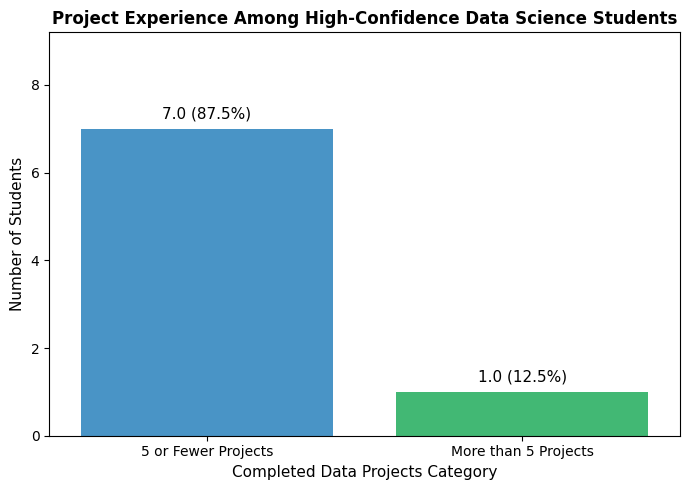

In [127]:
fig, ax = plt.subplots(figsize=(7, 5))

# Create a categorical column for visualization
high_conf_students_copy = high_conf_students.copy()
high_conf_students_copy["Project Category"] = np.where(
    high_conf_students_copy["projects_count"] <= 5,
    "5 or Fewer Projects",
    "More than 5 Projects",
)

# Plot proportions
sns.countplot(
    data=high_conf_students_copy,
    x="Project Category",
    palette=["#3498db", "#2ecc71"],
    ax=ax,
    order=["5 or Fewer Projects", "More than 5 Projects"],
)

# Annotate bars with exact counts and percentages
for p in ax.patches:
    height = p.get_height()
    percentage = (height / total_high_conf) * 100
    ax.annotate(
        f"{height} ({percentage:.1f}%)",
        (p.get_x() + p.get_width() / 2.0, height),
        ha="center",
        va="bottom",
        fontsize=11,
        xytext=(0, 5),
        textcoords="offset points",
    )

ax.set_title(
    "Project Experience Among High-Confidence Data Science Students",
    fontsize=12,
    fontweight="bold",
)
ax.set_xlabel("Completed Data Projects Category", fontsize=11)
ax.set_ylabel("Number of Students", fontsize=11)
ax.set_ylim(0, total_high_conf * 1.15)  # Leave room for labels

plt.tight_layout()
plt.show()

Among students reporting high overall confidence in data science (n= 8), the vast majority (87.5%) have completed 5 or fewer multi-week data projects. In contrast, only 12.5% of high confidence respondents reported completing more than 5 data projects. This indicates that high overall self-efficacy in data science is frequently present even among students with relatively limited project-based experience.


### Research question 2: Research question: Does a student’s prior familiarity with statistical terms significantly predict their overall Data Science confidence score?


In [132]:
df_ds["stat_index"] = df_ds[
    [
        "pearsons_r",
        "spearmans_r",
        "correlation_coefficient",
        "r_squared",
        "spline",
        "effect_sizes",
        "odds_ratio",
        "logistic_regression",
        "multiple_regression",
        "cohens_d",
        "SMD",
        "independent_groups",
        "repeated_measures",
        "ANOVA",
        "ANCOVA",
        "MANCOVA",
        "percentile",
        "percentile_rank",
        "t_test",
        "chi_square",
        "preregistration",
        "meta_analysis",
        "split_half",
        "z_score",
        "IQR",
        "measurements",
        "prediction_interval",
        "confidence_interval"
    ]
].mean(axis=1)

# Fit Simple OLS Regression
X = sm.add_constant(df_ds["stat_index"])
Y = df_ds["overall_confidence"]
model = sm.OLS(Y, X).fit()
print(model.summary())


                            OLS Regression Results                            
Dep. Variable:     overall_confidence   R-squared:                       0.355
Model:                            OLS   Adj. R-squared:                  0.248
Method:                 Least Squares   F-statistic:                     3.309
Date:                Sun, 13 Sep 2026   Prob (F-statistic):              0.119
Time:                        16:33:47   Log-Likelihood:                -5.5012
No. Observations:                   8   AIC:                             15.00
Df Residuals:                       6   BIC:                             15.16
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         10.8120      2.036      5.309      0.0

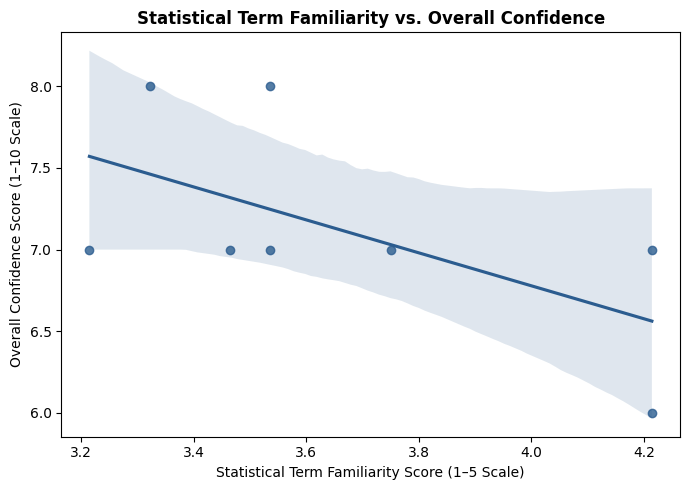

In [146]:
# Plot Regression Trendline
fig, ax = plt.subplots(figsize=(7, 5))
sns.regplot(
    data=df_ds,
    x="stat_index",
    y="overall_confidence",
    color="#2b5c8f",
    ax=ax,
)
ax.set_title(
    "Statistical Term Familiarity vs. Overall Confidence", fontweight="bold"
)
ax.set_xlabel("Statistical Term Familiarity Score (1–5 Scale)")
ax.set_ylabel("Overall Confidence Score (1–10 Scale)")
plt.tight_layout()
plt.show()

Contrary to intuitive expectations, the visualization reveals a slight negative association between a student's familiarity with statistical terms and their overall Data Science confidence score. As familiarity scores increase from approximately 3.2 to 4.2, the fitted regression line trends downward from an overall confidence score near 7.6 down to roughly 6.6. Furthermore, the wide shaded 95% confidence interval band. It expands significantly at higher familiarity levels, which indicates substantial variance. Consequently, prior familiarity with statistical terms alone does not serve as a reliable or positive predictor of overall Data Science confidence.